# TP 2 — Partie D : PLM gelé comme extracteur de représentations

Ce notebook implémente la **Partie D** du TP avec le modèle pré-entraîné sur des tweets **AraBERT** (`aubmindlab/bert-base-arabertv02-twitter`) :
1. **D1. Représentations globales fixes $\rightarrow$ Régression Logistique :**
   - Comparaison entre le vecteur **`[CLS]`** et la **moyenne des tokens pondérée** par le masque d'attention (*Mean Pooling*).
   - Régression logistique (`class_weight='balanced'`), recherche du seuil optimal sur `val`.
2. **D2. États de tous les tokens $\rightarrow$ Tête BiLSTM + Attention custom de C2 :**
   - Encodeur AraBERT gelé (*frozen*, 0 paramètre entraîné dans l'encodeur).
   - Tête récurrente BiLSTM (entrée 768d) suivie de la couche d'attention personnalisée du cours : $\alpha_i = \text{softmax}(v^\top \tanh(W h_i))$.
3. **Visualisation officielle de l'attention sur 5 tweets sarcastiques (Figure demandée en page 5 du compte-rendu) :**
   - Extraction des poids d'attention $\alpha_i$ sur 5 tweets sarcastiques réels.
   - Génération et sauvegarde de la figure haute résolution dans `results/attention_d2_5_tweets.png`.
4. Journalisation dans `results/results.csv` via `ajouter_resultat`.

In [1]:
# 1. Environnement et configuration
import os, sys
REPO = "/content/tp2-sarcasme-arabe"
if not os.path.exists(REPO):
    !git clone https://github.com/AbdelhamidRb/tp2-sarcasme-arabe.git
os.chdir(REPO)
if REPO not in sys.path:
    sys.path.insert(0, REPO)
!git pull

# Installation des bibliothèques nécessaires
!pip install -q transformers arabert pyarabic emoji arabic-reshaper python-bidi

Cloning into 'tp2-sarcasme-arabe'...
remote: Enumerating objects: 73, done.
remote: Counting objects: 100% (73/73), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 73 (delta 30), reused 57 (delta 14), pack-reused 0 (from 0)
Receiving objects: 100% (73/73), 75.03 KiB | 1.04 MiB/s, done.
Resolving deltas: 100% (30/30), done.
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 13.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 15.5 MB/s eta 0:00:00


In [2]:
# 2. Chargement des données et déduplication de train
import torch
import pandas as pd
import numpy as np
from src.seed import set_seed
from src.data import load_splits
from src.preprocess import dedupliquer_train
from src.results import ajouter_resultat, CHEMIN

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

train_brut, val, test = load_splits(seed=42)
train = dedupliquer_train(train_brut, test, verbose=True)
print(f"Tailles : train={len(train)} | val={len(val)} | test={len(test)} (test scellé)")

Appareil utilisé : cuda
train avant : 11293
  fuite retirée (présents dans test) : 4
  groupes contradictoires retirés    : 13
train après : 11217
Tailles : train=11217 | val=1255 | test=3000 (test scellé)


## 1. Prétraitement AraBERT et Tokenisation
Nous utilisons le préprocesseur officiel d'AraBERT (`ArabertPreprocessor`) pour normaliser le texte conformément au pré-entraînement du modèle.

In [3]:
from transformers import AutoTokenizer, AutoModel
from arabert.preprocess import ArabertPreprocessor
from torch.utils.data import Dataset, DataLoader

MODEL_NAME = "aubmindlab/bert-base-arabertv02-twitter"

print("Chargement du préprocesseur et tokenizer AraBERT-twitter...")
prep = ArabertPreprocessor(model_name=MODEL_NAME)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Application du prétraitement AraBERT sur les tweets
print("Prétraitement des tweets train et val...")
train_texts = [prep.preprocess(t) for t in train["tweet"]]
val_texts = [prep.preprocess(t) for t in val["tweet"]]

class ArabertDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=64):
        self.encodings = tokenizer(texts, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt")
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["label"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

BATCH_SIZE = 64
ds_train = ArabertDataset(train_texts, train["sarcasm"].astype(int).values, tokenizer, max_len=64)
ds_val = ArabertDataset(val_texts, val["sarcasm"].astype(int).values, tokenizer, max_len=64)

loader_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=False)
loader_val = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False)

# Chargement du modèle AraBERT gelé
arabert_model = AutoModel.from_pretrained(MODEL_NAME).to(device)
arabert_model.eval()
for p in arabert_model.parameters():
    p.requires_grad = False
print("AraBERT chargé et 100% gelé (requires_grad = False) !")

Chargement du préprocesseur et tokenizer AraBERT-twitter...


config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/751k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


AraBERT chargé et 100% gelé (requires_grad = False) !


## 2. Partie D1 : Représentations globales fixes $\rightarrow$ Régression Logistique
Comparaison de deux extracteurs de représentations :
- **D1.1 : Token `[CLS]`** (`last_hidden_state[:, 0, :]`)
- **D1.2 : Moyenne pondérée par le masque d'attention** (*Mean Pooling*)

In [4]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, accuracy_score
from src.train_d import extract_arabert_features
from src.train_c import find_best_threshold

# D1.1 : Extraction [CLS]
print("Extraction des caractéristiques [CLS] sur train et val...")
t0 = time.time()
X_train_cls, y_train = extract_arabert_features(arabert_model, loader_train, device, pooling="cls")
X_val_cls, y_val = extract_arabert_features(arabert_model, loader_val, device, pooling="cls")
t_extract_cls = time.time() - t0
print(f"Extraction terminée en {t_extract_cls:.1f}s. Forme train : {X_train_cls.shape}")

# Entraînement de la Régression Logistique sur [CLS]
t_train_start = time.time()
clf_cls = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
clf_cls.fit(X_train_cls, y_train)
t_train_cls = round(time.time() - t_train_start, 2)

proba_val_cls = clf_cls.predict_proba(X_val_cls)[:, 1]
seuil_cls, f1_cls = find_best_threshold(y_val, proba_val_cls)
pr_auc_cls = round(float(average_precision_score(y_val, proba_val_cls)), 4)
f1_05_cls = round(float(f1_score(y_val, proba_val_cls >= 0.5, zero_division=0)), 4)
acc_cls = round(float(accuracy_score(y_val, proba_val_cls >= seuil_cls)), 4)
n_params_cls = clf_cls.coef_.size + clf_cls.intercept_.size

print(f"D1.1 [CLS] | PR-AUC: {pr_auc_cls:.4f} | Seuil: {seuil_cls} | Val F1: {f1_cls:.4f} | F1@0.5: {f1_05_cls:.4f}")

ajouter_resultat({
    "modele": "D1. AraBERT gelé [CLS] + LogisticRegression",
    "preprocessing": "arabert_prep + [CLS] 768d",
    "graine": 42,
    "seuil": seuil_cls,
    "pr_auc_val": pr_auc_cls,
    "f1_sarc_val": f1_cls,
    "f1_sarc_val_seuil_0_5": f1_05_cls,
    "accuracy_val_seuil": acc_cls,
    "n_train": len(train),
    "n_val": len(val),
    "temps_entrainement_s": t_train_cls,
    "params_entraines": int(n_params_cls),
    "note": "seuil sur val, encodeur arabert gelé",
})

Extraction des caractéristiques [CLS] sur train et val...
Extraction terminée en 40.9s. Forme train : (11217, 768)
D1.1 [CLS] | PR-AUC: 0.6086 | Seuil: 0.64 | Val F1: 0.6166 | F1@0.5: 0.6000


In [5]:
# D1.2 : Extraction Moyenne des tokens (Mean Pooling)
print("Extraction des caractéristiques Moyenne des tokens (Mean Pooling) sur train et val...")
t0 = time.time()
X_train_mean, _ = extract_arabert_features(arabert_model, loader_train, device, pooling="mean")
X_val_mean, _ = extract_arabert_features(arabert_model, loader_val, device, pooling="mean")
t_extract_mean = time.time() - t0
print(f"Extraction terminée en {t_extract_mean:.1f}s. Forme train : {X_train_mean.shape}")

# Entraînement de la Régression Logistique sur Mean Pooling
t_train_start = time.time()
clf_mean = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
clf_mean.fit(X_train_mean, y_train)
t_train_mean = round(time.time() - t_train_start, 2)

proba_val_mean = clf_mean.predict_proba(X_val_mean)[:, 1]
seuil_mean, f1_mean = find_best_threshold(y_val, proba_val_mean)
pr_auc_mean = round(float(average_precision_score(y_val, proba_val_mean)), 4)
f1_05_mean = round(float(f1_score(y_val, proba_val_mean >= 0.5, zero_division=0)), 4)
acc_mean = round(float(accuracy_score(y_val, proba_val_mean >= seuil_mean)), 4)
n_params_mean = clf_mean.coef_.size + clf_mean.intercept_.size

print(f"D1.2 [Mean] | PR-AUC: {pr_auc_mean:.4f} | Seuil: {seuil_mean} | Val F1: {f1_mean:.4f} | F1@0.5: {f1_05_mean:.4f}")

ajouter_resultat({
    "modele": "D1. AraBERT gelé [Mean] + LogisticRegression",
    "preprocessing": "arabert_prep + mean pooling 768d",
    "graine": 42,
    "seuil": seuil_mean,
    "pr_auc_val": pr_auc_mean,
    "f1_sarc_val": f1_mean,
    "f1_sarc_val_seuil_0_5": f1_05_mean,
    "accuracy_val_seuil": acc_mean,
    "n_train": len(train),
    "n_val": len(val),
    "temps_entrainement_s": t_train_mean,
    "params_entraines": int(n_params_mean),
    "note": "seuil sur val, encodeur arabert gelé",
})

Extraction des caractéristiques Moyenne des tokens (Mean Pooling) sur train et val...
Extraction terminée en 45.0s. Forme train : (11217, 768)
D1.2 [Mean] | PR-AUC: 0.6184 | Seuil: 0.66 | Val F1: 0.6138 | F1@0.5: 0.6046


## 3. Partie D2 : États de tous les tokens $\rightarrow$ Tête BiLSTM + Attention custom de C2
L'encodeur AraBERT reste entièrement gelé. La séquence complète des états cachés (768d par token) alimente un BiLSTM (dim 128) surmonté de la couche d'attention personnalisée.

In [6]:
from src.models_d import AraBertFrozenBiLSTMAttention
from src.train_d import train_d2_model

set_seed(42)
# Création du modèle hybride D2
model_d2 = AraBertFrozenBiLSTMAttention(
    arabert_model=arabert_model,
    hidden_dim=128,
    att_dim=64,
    num_classes=2,
    dropout=0.3,
)

# Seuls les paramètres de la tête (BiLSTM + Attention + FC) sont optimisés !
params_to_train = [p for p in model_d2.parameters() if p.requires_grad]
print(f"Nombre de paramètres entraînables dans D2 : {sum(p.numel() for p in params_to_train):,} (AraBERT gelé)")

opt_d2 = torch.optim.Adam(params_to_train, lr=1e-3, weight_decay=1e-4)
crit_d2 = torch.nn.CrossEntropyLoss()

# Re-mélanger train pour l'entraînement PyTorch
loader_train_d2 = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True)

print("=== Entraînement D2 : AraBERT gelé + tête BiLSTM + Attention ===")
res_d2 = train_d2_model(model_d2, loader_train_d2, loader_val, opt_d2, crit_d2, device, epochs=10, patience=3)

ajouter_resultat({
    "modele": "D2. AraBERT gelé + BiLSTM + Attention custom",
    "preprocessing": "arabert_prep + tokens 768d",
    "graine": 42,
    "seuil": res_d2["seuil"],
    "pr_auc_val": res_d2["pr_auc_val"],
    "f1_sarc_val": res_d2["f1_sarc_val"],
    "f1_sarc_val_seuil_0_5": res_d2["f1_sarc_val_seuil_0_5"],
    "accuracy_val_seuil": res_d2["accuracy_val_seuil"],
    "n_train": len(train),
    "n_val": len(val),
    "temps_entrainement_s": res_d2["temps_entrainement_s"],
    "params_entraines": res_d2["params_entraines"],
    "note": "seuil sur val, AraBERT gelé + BiLSTM attention custom",
})

Nombre de paramètres entraînables dans D2 : 936,578 (AraBERT gelé)
=== Entraînement D2 : AraBERT gelé + tête BiLSTM + Attention ===
Epoch 01/10 | Loss: 0.3253 | PR-AUC: 0.6976 | Val F1 sarc: 0.6652 (seuil 0.32) | F1@0.5: 0.5899
Epoch 02/10 | Loss: 0.2793 | PR-AUC: 0.6994 | Val F1 sarc: 0.6624 (seuil 0.48) | F1@0.5: 0.6578
Epoch 03/10 | Loss: 0.2553 | PR-AUC: 0.6654 | Val F1 sarc: 0.6480 (seuil 0.32) | F1@0.5: 0.5378
Epoch 04/10 | Loss: 0.2286 | PR-AUC: 0.6566 | Val F1 sarc: 0.6424 (seuil 0.42) | F1@0.5: 0.6210
Early stopping déclenché à l'époque 4 (meilleur F1: 0.6652)


## 4. Visualisation de l'Attention sur 5 tweets sarcastiques (Figure officielle du compte-rendu)
Nous sélectionnons 5 tweets sarcastiques réels de l'ensemble de validation, extrayons les poids d'attention $\alpha_i$, et générons le tracé requis pour la page 5 du rapport.

/content/tp2-sarcasme-arabe/src/train_d.py:189: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(range(len(labels))), y=poids_norm, ax=ax, palette="mako")
/content/tp2-sarcasme-arabe/src/train_d.py:189: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(range(len(labels))), y=poids_norm, ax=ax, palette="mako")
/content/tp2-sarcasme-arabe/src/train_d.py:189: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(range(len(labels))), y=poids_norm, ax=ax, palette="mako")
/content/tp2-sarcasme-arabe/src/train_d.py:189: FutureWarning: 

Passi

Figure sauvegardée avec succès : results/attention_d2_5_tweets.png


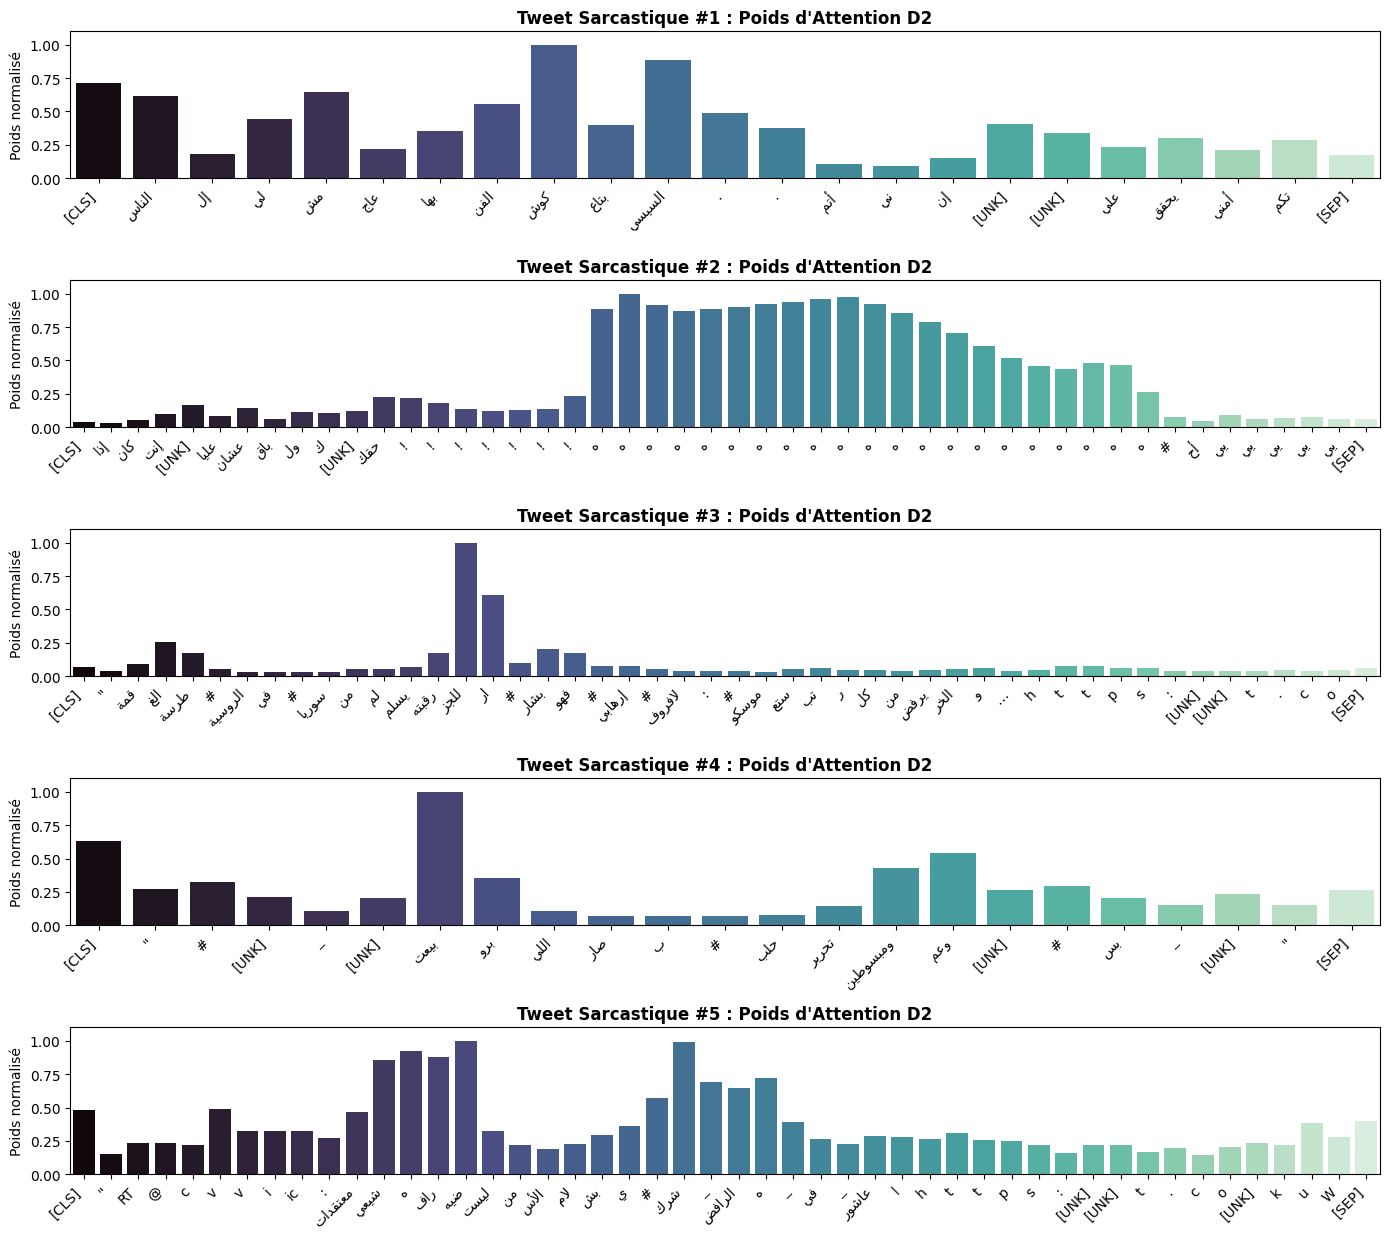

Figure sauvegardée dans results/attention_d2_5_tweets.png prête à être collée dans le compte-rendu (page 5) !


In [7]:
from src.train_d import plot_attention_visualization

# Sélection de 5 tweets sarcastiques représentatifs de val
tweets_sarcastiques = val[val["sarcasm"] == 1]["tweet"].head(5).tolist()

os.makedirs("results", exist_ok=True)
plot_attention_visualization(
    model=model_d2,
    tokenizer=tokenizer,
    tweets_list=tweets_sarcastiques,
    device=device,
    save_path="results/attention_d2_5_tweets.png",
)
print("Figure sauvegardée dans results/attention_d2_5_tweets.png prête à être collée dans le compte-rendu (page 5) !")

## 5. Tableau récapitulatif des résultats

In [8]:
df_res = pd.read_csv(CHEMIN)
print(df_res[["modele", "seuil", "pr_auc_val", "f1_sarc_val", "f1_sarc_val_seuil_0_5", "temps_entrainement_s", "params_entraines"]].to_string())


                                                 modele  seuil  pr_auc_val  f1_sarc_val  f1_sarc_val_seuil_0_5  temps_entrainement_s  params_entraines
0   TF-IDF + LogisticRegression (class_weight=balanced)   0.42      0.5217       0.5153                 0.5041                  4.81          186332.0
1                     mDeBERTa NLI zero-shot (français)   0.75      0.3495       0.4119                    NaN                   NaN               NaN
2              CAMeL sentiment, règle négatif=>sarcasme    NaN         NaN       0.4656                    NaN                   NaN               NaN
3                      C1. BiLSTM (embedding aléatoire)   0.26      0.4230       0.4453                 0.3563                 22.63         5353634.0
4                              C1. BiLSTM (AraVec figé)   0.12      0.4699       0.4969                 0.3028                 13.66          440834.0
5                            C1. BiLSTM (AraVec dégelé)   0.18      0.5026       0.5074       